In [1]:
%pip install pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import os
train_path = 'data/train.csv' if os.path.exists('data/train.csv') else 'data/train_sample.csv'
df = pd.read_csv(train_path, parse_dates=['Date'], encoding='utf-8')
store = pd.read_csv('data/store.csv', encoding='utf-8')

# Merge store metadata into the sales data
df = df.merge(store, on='Store', how='left')

print(df.shape)
print(df.head())
print(df.dtypes)



<>:5: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:5: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\havya\AppData\Local\Temp\ipykernel_10700\2953725193.py:5: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  store = pd.read_csv('data/store.csv', encoding='utf-8')
C:\Users\havya\AppData\Local\Temp\ipykernel_10700\2953725193.py:4: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/train.csv', parse_dates=['Date'], encoding='utf-8')


(1017209, 18)
   Store  DayOfWeek       Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5 2015-07-31   5263        555     1      1            0   
1      2          5 2015-07-31   6064        625     1      1            0   
2      3          5 2015-07-31   8314        821     1      1            0   
3      4          5 2015-07-31  13995       1498     1      1            0   
4      5          5 2015-07-31   4822        559     1      1            0   

   SchoolHoliday StoreType Assortment  CompetitionDistance  \
0              1         c          a               1270.0   
1              1         a          a                570.0   
2              1         a          a              14130.0   
3              1         c          c                620.0   
4              1         a          a              29910.0   

   CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  \
0                        9.0                    2008.0       0   
1           

In [3]:
#### Step 2 — Check for missing values and obvious problems
print(df.isnull().sum())

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


In [4]:
# Drop rows where the store was closed (Sales = 0 on closed days skews the model)
df= df[df['Open'] == 1].copy()
print(f"rows after store closed: {len(df)}")

rows after store closed: 844392


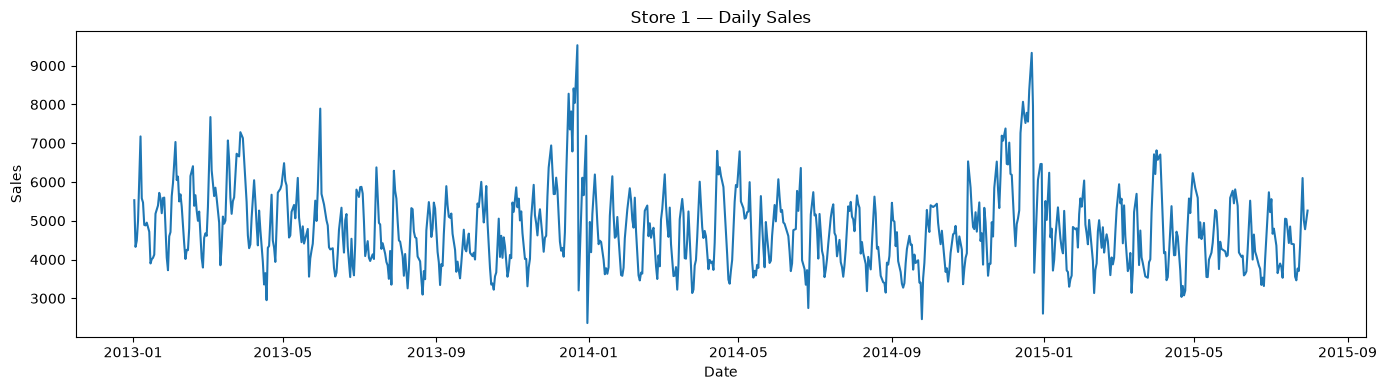

In [5]:
#plot the sales trend
# Pick a single store to start simple
store1 = df[df['Store'] == 1].sort_values('Date')
plt.figure(figsize=(14, 4))
plt.plot(store1['Date'], store1['Sales'])
plt.title('Store 1 — Daily Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

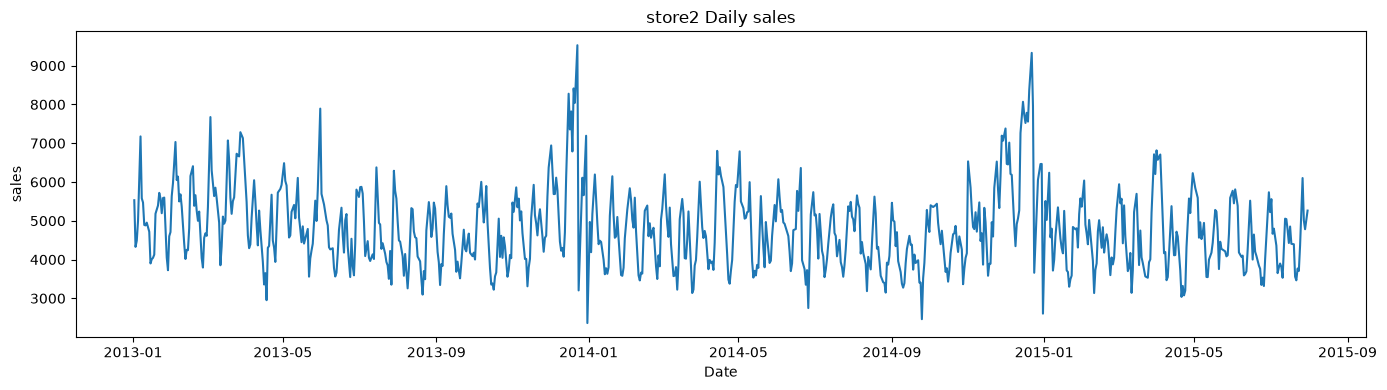

In [6]:
store2 = df[df['Store'] == 1].sort_values('Date')

plt.figure(figsize=(14,4))
plt.plot(store2['Date'], store2['Sales'])
plt.title('store2 Daily sales')
plt.xlabel('Date')
plt.ylabel('sales')
plt.tight_layout()
plt.show()

In [7]:

df['Year'] = df['Date'].dt.isocalendar().year                          #### Step 1 — Extract date-based features 
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['DayOfMonth'] = df['Date'].dt.day
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

In [8]:
#### Step 2 — Create lag features

#Lag features tell the model what sales looked like in the past. They're critical for time-series forecasting.

df = df.sort_values(['Store', 'Date'])

# Sales from 1, 7, and 14 days ago
df['Sales_lag1'] = df.groupby('Store')['Sales'].shift(1)
df['Sales_lag7'] = df.groupby('Store')['Sales'].shift(7)
df['Sales_lag14'] = df.groupby('Store')['Sales'].shift(14)


In [9]:
### Step 3 — Add rolling averages

#Rolling averages smooth out noise and capture recent trends.

df['Sales_roll7'] = df.groupby('Store')['Sales'].transform(
    lambda x: x.shift(1).rolling(7).mean()
)
df['Sales_roll30'] = df.groupby('Store')['Sales'].transform(
    lambda x: x.shift(1).rolling(30).mean()
)

In [10]:
#### Step 4 — Drop NaN rows created by lags and split by date

df = df.dropna()

# Use the last 6 weeks as the test set
split_date = '2015-06-01'
train = df[df['Date'] < split_date]
test  = df[df['Date'] >= split_date]

print(f"Train size: {len(train)}, Test size: {len(test)}")

Train size: 237789, Test size: 19073


In [11]:
#Train Your First Models

#**Goal:** Train and compare multiple models, track experiments with MLflow, and save the best model to disk.

#### Step 1 — Define features and target
feature_cols = [
    'Store', 'DayOfWeek', 'Month', 'Year', 'Week',
    'IsWeekend', 'Promo', 'SchoolHoliday',
    'Sales_lag1', 'Sales_lag7', 'Sales_lag14',
    'Sales_roll7', 'Sales_roll30'
]

X_train = train[feature_cols]
y_train = train['Sales']
X_test  = test[feature_cols]
y_test  = test['Sales']

In [12]:
#### Step 2 — Baseline linear regression

#Always start with a simple model. It tells you how much value the more complex models are actually adding.
%pip install scikit-learn



Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)

mae = mean_absolute_error(y_test, lr_preds)
rmse = np.sqrt(mean_squared_error(y_test, lr_preds))
print(f"Linear Regression — MAE: {mae:.0f}, RMSE: {rmse:.0f}")

Linear Regression — MAE: 904, RMSE: 1248


In [14]:
%pip install mlflow xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -------- ------------------------------- 11.0/48.9 MB 59.7 MB/s eta 0:00:01
   ------------------- -------------------- 23.3/48.9 MB 59.4 MB/s eta 0:00:01
   ------------------------------ --------- 37.2/48.9 MB 60.8 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 61.9 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 47.7 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:

#### Step 3 — XGBoost model with MLflow tracking

import mlflow
import mlflow.xgboost
from xgboost import XGBRegressor

mlflow.set_experiment("demand-forecasting")

with mlflow.start_run(run_name="xgboost-v1"):
    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42
    )
    model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

    preds = model.predict(X_test)
    mae  = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.xgboost.log_model(model, "model")

    print(f"XGBoost — MAE: {mae:.0f}, RMSE: {rmse:.0f}")

2026/08/13 12:30:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/13 12:30:11 INFO mlflow.store.db.utils: Updating database tables
2026/08/13 12:30:14 INFO mlflow.tracking.fluent: Experiment with name 'demand-forecasting' does not exist. Creating a new experiment.
2026/08/13 12:30:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


XGBoost — MAE: 692, RMSE: 964


In [19]:
#### Step 4 — Save the best model to disk
import joblib

joblib.dump(model, 'models/model.pkl')
joblib.dump(feature_cols, 'models/feature_cols.pkl')
print("Model saved.")

#joblib.dump(model, 'model.pkl.gz', compress=3)  # 1–9, higher = smaller file

Model saved.


In [21]:
%pip install prophet

Defaulting to user installation because normal site-packages is not writeable
  Using cached prophet-1.3.0-py3-none-win_amd64.whl.metadata (3.6 kB)
  Using cached cmdstanpy-1.3.0-py3-none-any.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.0-py3-none-any.whl.metadata (57 kB)
  Using cached importlib_resources-7.1.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached stanio-0.5.1-py3-none-any.whl.metadata (1.6 kB)
Using cached prophet-1.3.0-py3-none-win_amd64.whl (12.1 MB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ------------- -------------------------- 0.5/1.6 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 5.3 MB/s  0:00:00
Using cached cmdstanpy-1.3.0-py3-none-any.whl (99 kB)
Using cached stanio-0.5.1-py3-none-any.whl (8.1 kB)
Using cached tqdm-4.70.0-py3-none-any.whl (80 kB)
Using cached importlib_resources-7.1.0-py3-none-any.whl (37 kB)

   ---------------------------------------- 0/6 [tqdm]
   -----------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
#optional prophet without feature engineering

from prophet import Prophet

store1_train = (
    df[df['Store'] == 1]          # adjust filter as needed
    .rename(columns={'Date': 'ds', 'Sales': 'y'})
    [['ds', 'y']]                  # keep only required columns
    .dropna(subset=['y'])          # drop NaN rows
    .copy()
)

store1_train['ds'] = pd.to_datetime(store1_train['ds'])

print(store1_train.shape)         # confirm > 2 rows
print(store1_train.head())

m = Prophet(yearly_seasonality=True, weekly_seasonality=True)
m.fit(store1_train)

(0, 2)
Empty DataFrame
Columns: [ds, y]
Index: []


ValueError: Dataframe has less than 2 non-NaN rows.

API + Deployment
Create the following files in your project folder:

```
project/
├── data/
├── model.pkl
├── feature_cols.pkl
├── main.py          ← your FastAPI app
├── Dockerfile
└── dashboard.py     ← Streamlit app

Write the FastAPI app

Create `main.py`: